# 2. Data Analytics

What the brief asks for, and where each part is answered:

| Brief | Section |
|---|---|
| Portfolio profiling across key dimensions: income, employment type, region, age, loan type | 2.2 |
| 4-5 concrete insights with a "so what" (e.g. segment X = Y% of exposure, Z% higher default rate) | 2.6 |
| At least one cross-dimensional cut (e.g. income x employment, or region x loan type) | 2.4 (both) |

**Data:** `data/processed/accounts_clean.csv` (notebook 1). All tables come from `src/portfolio.py`, the same code the
dashboard uses.

**Definitions:** *default rate* = share of accounts with `target_default = 1`; *exposure* = original loan amount;
*lift* = segment default rate / portfolio default rate; *share of defaulted exposure* = the segment's share of the
exposure on loans that defaulted.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import json
import pandas as pd
import matplotlib.pyplot as plt
from nbstyle import BLUE, ORANGE, STATUS, rate_barh, paired_barh, heatmap
import portfolio as pf
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)
book = pf.load_book()

## 2.1 Portfolio at a glance

In [2]:
o = pf.overview(book)
pd.Series({
    "Loan accounts": f"{o['accounts']:,}",
    "Customers": f"{o['customers']:,}",
    "Exposure (original loan amount)": f"${o['exposure'] / 1e6:,.1f}M",
    "Default rate (accounts)": f"{o['default_rate']:.1%}",
    "Defaulted accounts": f"{o['defaulted_accounts']:,}",
    "Share of exposure on defaulted loans": f"{o['defaulted_exposure_share']:.1%}",
}, name="value").to_frame()

,value
Loan accounts,"14,685"
Customers,"10,000"
Exposure (original loan amount),$601.1M
Default rate (accounts),16.1%
Defaulted accounts,"2,364"
Share of exposure on defaulted loans,21.1%


## 2.2 Profiling across the five key dimensions

For each dimension: the default rate per segment (left) and where the money sits versus where the defaulted money
sits (right). A segment whose orange bar is longer than its blue bar carries more than its share of losses.

In [3]:
COLUMNS = ["segment", "accounts", "account_share", "exposure_share", "default_rate", "lift",
           "share_of_defaulted_exposure"]

def profile(dim, title):
    table = pf.segment_summary(book, dim)
    if dim not in pf.ORDER:
        table = table.sort_values("default_rate", ascending=False)
    fig, (left, right) = plt.subplots(1, 2, figsize=(11, 0.55 * len(table) + 1.4))
    rate_barh(left, table.segment, table.default_rate, average=book.target_default.mean(),
              title=f"Default rate by {title}")
    paired_barh(right, table.segment, table.exposure_share, table.share_of_defaulted_exposure,
                ["Share of exposure", "Share of defaulted exposure"], title="Exposure vs defaulted exposure")
    right.set_yticklabels([])
    plt.tight_layout()
    plt.show()
    return table[COLUMNS].style.format({c: "{:.1%}" for c in COLUMNS[2:] if c != "lift"} | {"lift": "{:.2f}x"})

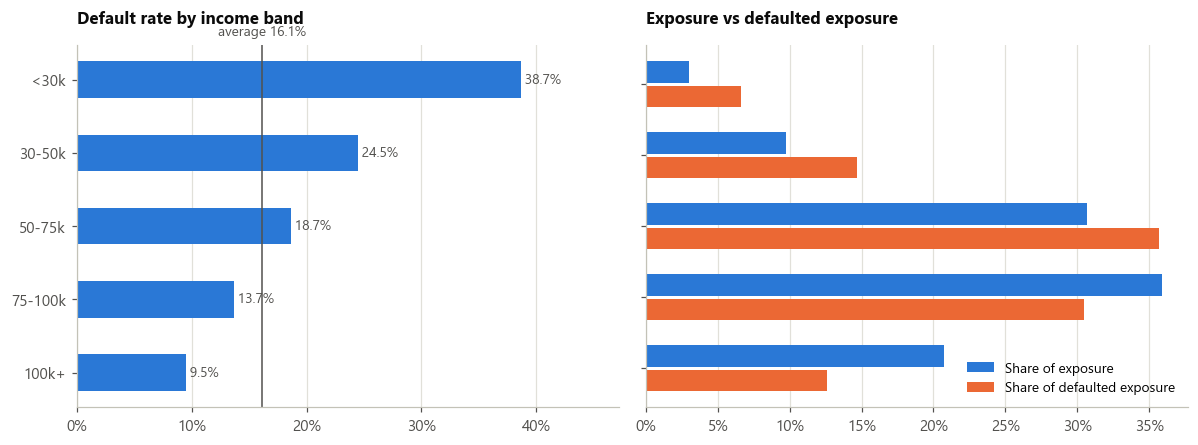

,segment,accounts,account_share,exposure_share,default_rate,lift,share_of_defaulted_exposure
0,<30k,450,3.1%,3.0%,38.7%,2.40x,6.6%
1,30-50k,1390,9.5%,9.7%,24.5%,1.52x,14.7%
2,50-75k,4466,30.4%,30.6%,18.7%,1.16x,35.7%
3,75-100k,5281,36.0%,35.9%,13.7%,0.85x,30.4%
4,100k+,3098,21.1%,20.7%,9.5%,0.59x,12.6%


In [4]:
profile('income_band', 'income band')

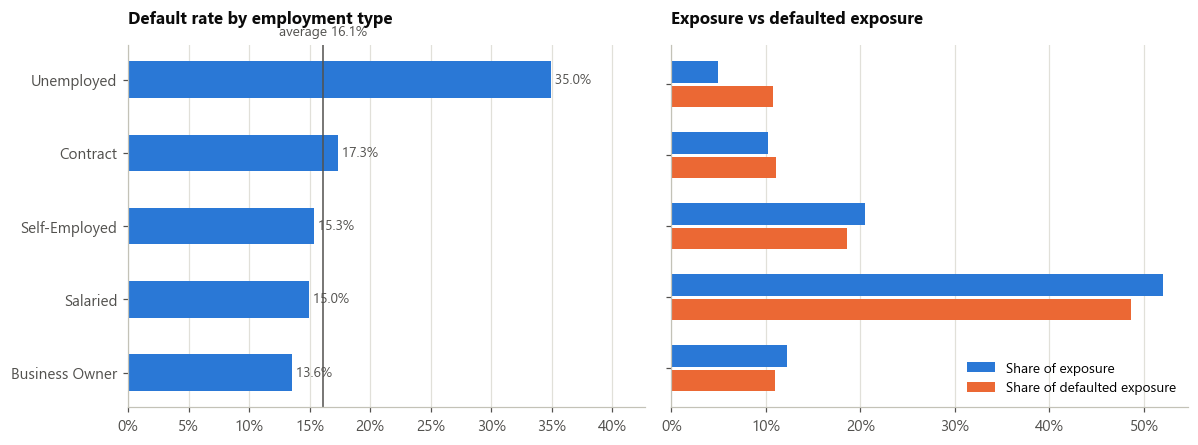

,segment,accounts,account_share,exposure_share,default_rate,lift,share_of_defaulted_exposure
4,Unemployed,718,4.9%,4.9%,35.0%,2.17x,10.8%
1,Contract,1563,10.6%,10.2%,17.3%,1.08x,11.0%
3,Self-Employed,3014,20.5%,20.5%,15.3%,0.95x,18.6%
2,Salaried,7546,51.4%,52.1%,15.0%,0.93x,48.7%
0,Business Owner,1844,12.6%,12.2%,13.6%,0.84x,10.9%


In [5]:
profile('employment_type', 'employment type')

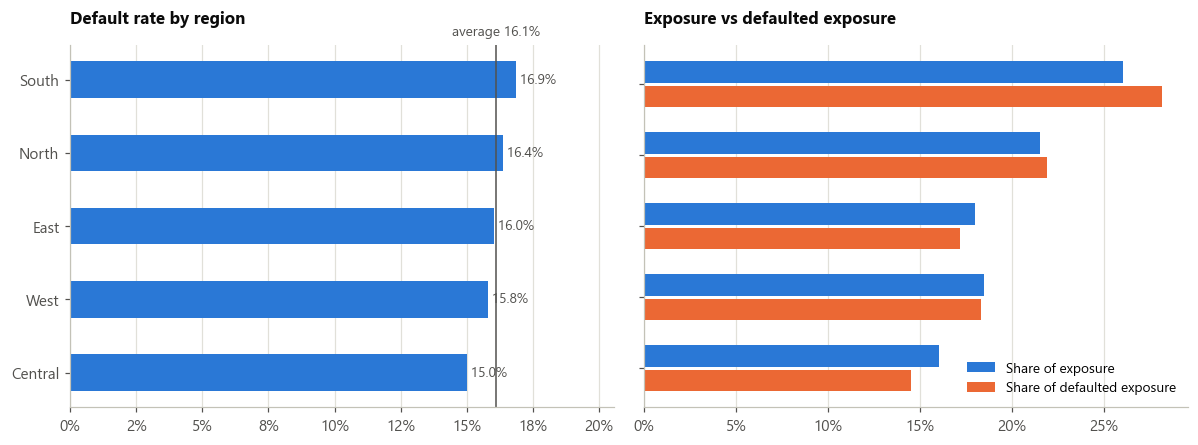

,segment,accounts,account_share,exposure_share,default_rate,lift,share_of_defaulted_exposure
3,South,3600,24.5%,26.0%,16.9%,1.05x,28.1%
2,North,3147,21.4%,21.5%,16.4%,1.02x,21.9%
1,East,2747,18.7%,18.0%,16.0%,0.99x,17.2%
4,West,2877,19.6%,18.4%,15.8%,0.98x,18.3%
0,Central,2314,15.8%,16.0%,15.0%,0.93x,14.5%


In [6]:
profile('region', 'region')

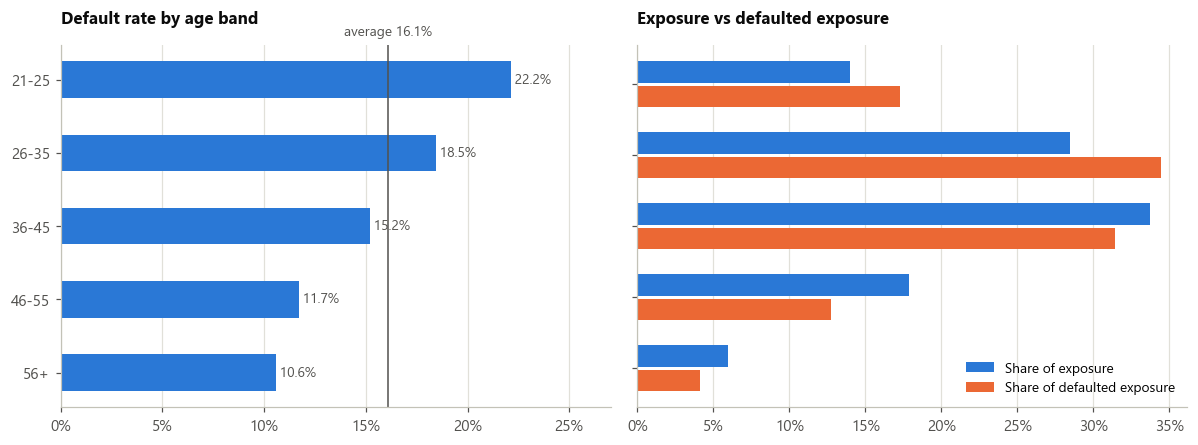

,segment,accounts,account_share,exposure_share,default_rate,lift,share_of_defaulted_exposure
0,21-25,1927,13.1%,14.0%,22.2%,1.38x,17.3%
1,26-35,4070,27.7%,28.5%,18.5%,1.15x,34.4%
2,36-45,5097,34.7%,33.7%,15.2%,0.94x,31.4%
3,46-55,2758,18.8%,17.9%,11.7%,0.73x,12.7%
4,56+,833,5.7%,5.9%,10.6%,0.66x,4.1%


In [7]:
profile('age_band', 'age band')

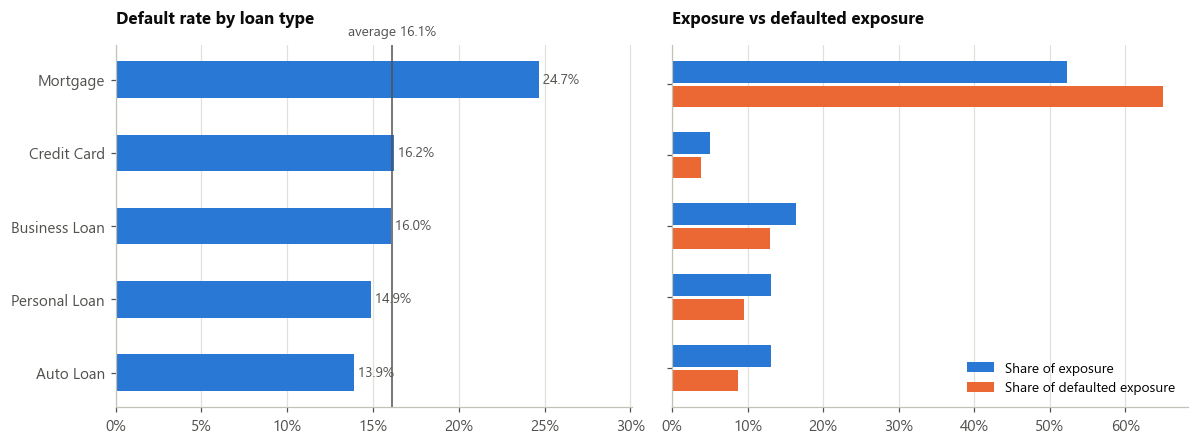

,segment,accounts,account_share,exposure_share,default_rate,lift,share_of_defaulted_exposure
3,Mortgage,1432,9.8%,52.3%,24.7%,1.53x,65.0%
2,Credit Card,3721,25.3%,5.0%,16.2%,1.01x,3.8%
1,Business Loan,1484,10.1%,16.5%,16.0%,1.00x,12.9%
4,Personal Loan,5216,35.5%,13.1%,14.9%,0.93x,9.5%
0,Auto Loan,2832,19.3%,13.1%,13.9%,0.86x,8.7%


In [8]:
profile('loan_type', 'loan type')

**Reading the profiles**

- **Income** has the steepest gradient: from 38.7% default under \$30k to 9.5% at \$100k+.
- **Unemployed** borrowers default at 35.0%; the four employed groups sit within 13.6%–17.3%.
- **Region** barely separates risk (15.0%–16.9%).
- **Age**: 21–25 year-olds default at 22.2% against 10.6% for 56+. Age is still kept out of the model for fair-lending
  reasons (see notebook 3): dropping it cost no accuracy.
- **Mortgages** default most (24.7%) and, because they are large, hold 52.3% of exposure and 65.0% of defaulted
  exposure.

## 2.3 Affordability

Two ratios built during ingestion: the monthly instalment as a share of monthly income, and the loan amount as a
multiple of annual income.

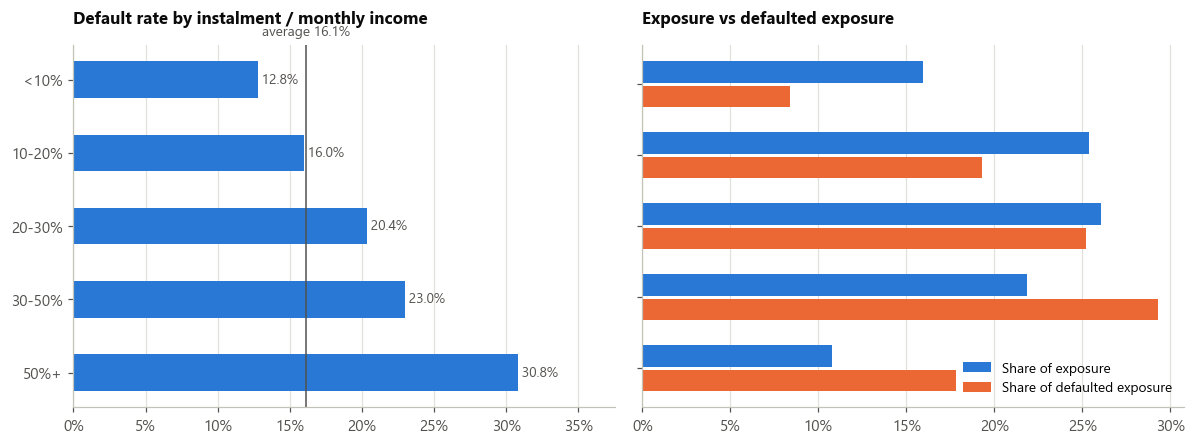

,segment,accounts,account_share,exposure_share,default_rate,lift,share_of_defaulted_exposure
0,<10%,7211,49.1%,16.0%,12.8%,0.80x,8.4%
1,10-20%,4007,27.3%,25.4%,16.0%,0.99x,19.3%
2,20-30%,1729,11.8%,26.0%,20.4%,1.26x,25.2%
3,30-50%,1147,7.8%,21.8%,23.0%,1.43x,29.3%
4,50%+,591,4.0%,10.8%,30.8%,1.91x,17.8%


In [9]:
profile('emi_to_income_band', 'instalment / monthly income')

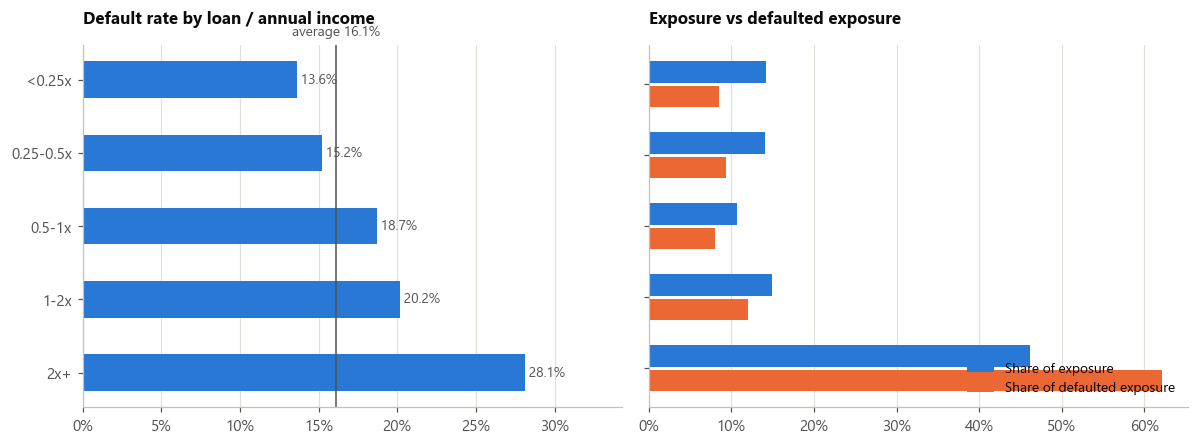

,segment,accounts,account_share,exposure_share,default_rate,lift,share_of_defaulted_exposure
0,<0.25x,7835,53.4%,14.1%,13.6%,0.85x,8.5%
1,0.25-0.5x,3351,22.8%,14.1%,15.2%,0.95x,9.3%
2,0.5-1x,1366,9.3%,10.7%,18.7%,1.16x,8.0%
3,1-2x,873,5.9%,14.9%,20.2%,1.25x,12.0%
4,2x+,1260,8.6%,46.2%,28.1%,1.75x,62.2%


In [10]:
profile('lti_band', 'loan / annual income')

## 2.4 Cross-dimensional cuts

Cells are coloured by distance from the portfolio average (16.1%): red above, blue below. `*` marks cells with fewer
than 100 accounts.

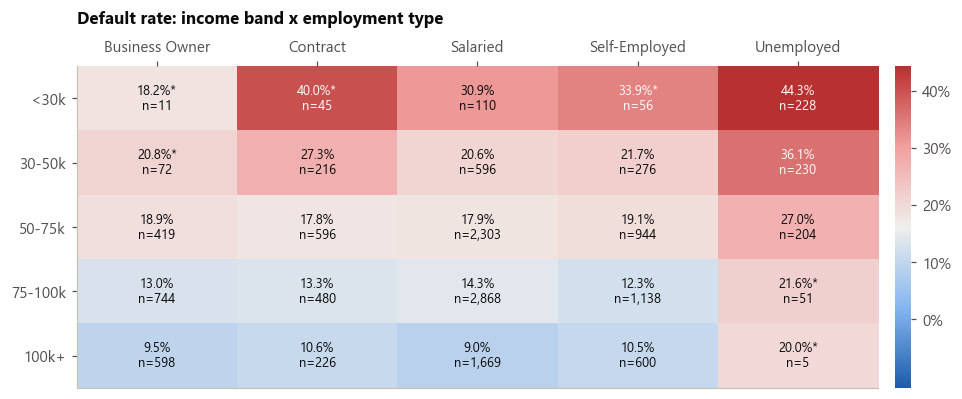

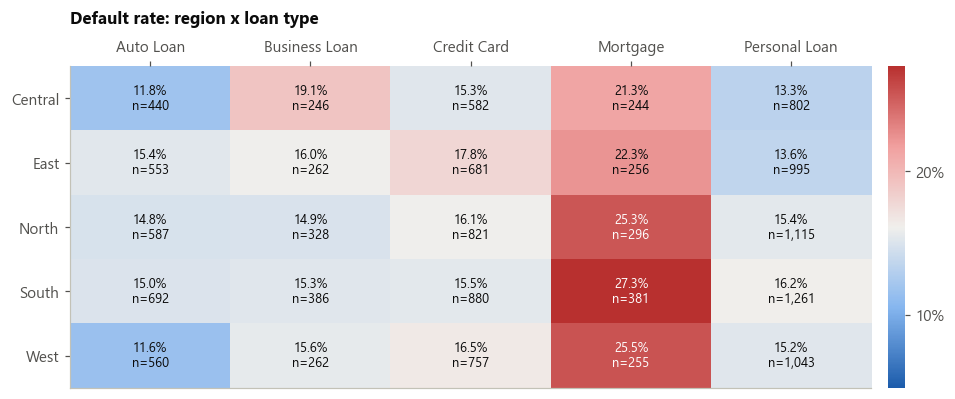

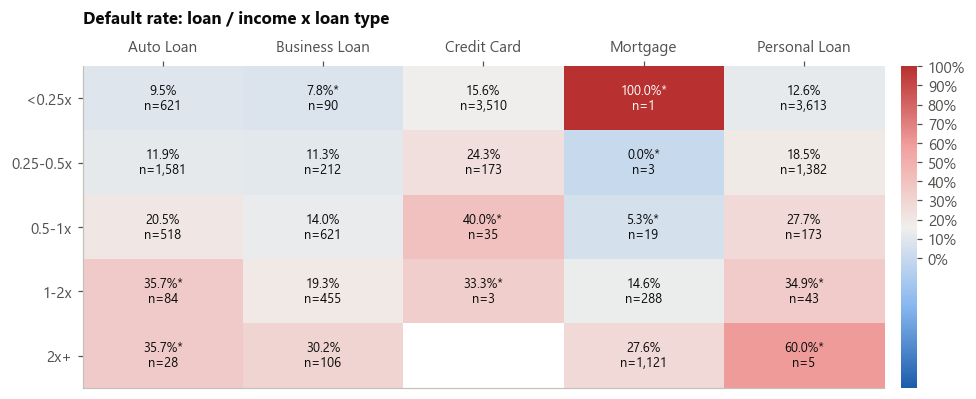

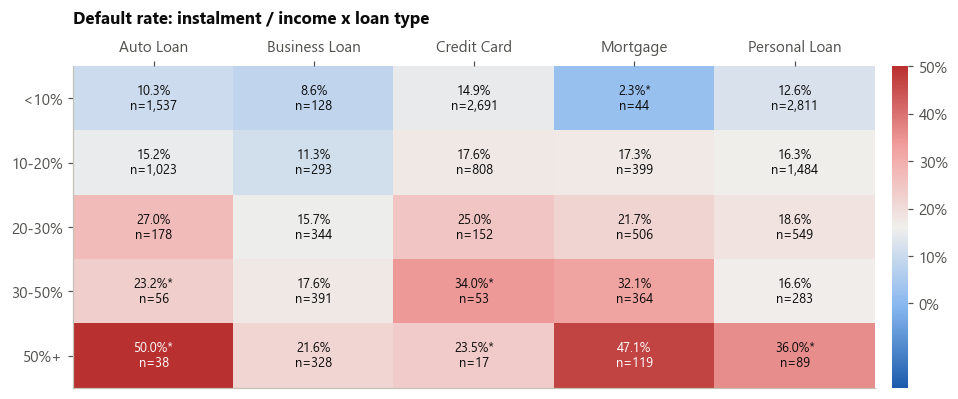

Median loan / annual income: Mortgage 2.8x, Other products 0.2x


In [11]:
for row, col, title in [("income_band", "employment_type", "Default rate: income band x employment type"),
                        ("region", "loan_type", "Default rate: region x loan type"),
                        ("lti_band", "loan_type", "Default rate: loan / income x loan type"),
                        ("emi_to_income_band", "loan_type", "Default rate: instalment / income x loan type")]:
    rate, count = pf.cross_tab(book, row, col)
    fig, ax = plt.subplots(figsize=(10, 3.8))
    heatmap(ax, rate, count, book.target_default.mean(), title=title)
    plt.show()

product = book.loan_type.eq("Mortgage").map({True: "Mortgage", False: "Other products"})
print("Median loan / annual income:", ", ".join(f"{k} {v:.1f}x" for k, v in
                                               book.groupby(product).loan_to_income.median().items()))

- **Income x employment:** unemployed customers earning under \$30k default at 44.3% (228 accounts), against 9.0%
  for salaried customers on \$100k+ (1,669 accounts). Being unemployed adds risk at *every* income level (27.0% at
  \$50–75k vs 17.8–19.1% for employed groups).
- **Region x loan type:** mortgages default at 21.3%–27.3% in every region, while other products stay within
  11.6%–19.1%. The worst cell is South mortgages (27.3%, 381 accounts). Product drives the risk, not geography.
- **Loan / income x loan type:** inside every product, default rises with loan-to-income (auto loans 9.5% below 0.25x
  to 35.7% at 1–2x). Mortgages sit almost entirely at 1x and above (median 2.8x annual income, against 0.2x for other products),
  which is why they look so risky.
- **Instalment / income x loan type:** the affordability effect is not a product mix: inside each product the top
  band defaults more than the bottom one. Mortgages go from 17.3% at 10–20% of income (399 accounts) to 47.1% above
  half of income (119 accounts).

## 2.5 Trend and behaviour signals

In [12]:
trend = pf.vintage_trend(book, "origination_year")
display(trend.style.format({"default_rate": "{:.1%}", "avg_predicted_pd": "{:.1%}", "exposure": "${:,.0f}"}))

signals = pd.DataFrame({
    "Any written-off line at the bureau": book.groupby("bureau_any_written_off").target_default.mean(),
    "No bureau record": book.groupby("bureau_no_file").target_default.mean(),
    "Missed 1+ payment in first 12 months": book.groupby(book.rep_n_missed.gt(0).astype(int)).target_default.mean(),
}).T.rename(columns={0: "no", 1: "yes"})
signals.style.format("{:.1%}")

,origination_year,accounts,exposure,default_rate,avg_predicted_pd
0,2018,2487,"$100,454,432",16.6%,16.1%
1,2019,2434,"$97,992,997",15.7%,16.0%
2,2020,2396,"$99,316,040",14.9%,16.1%
3,2021,2447,"$103,965,384",17.7%,16.3%
4,2022,2451,"$98,581,713",16.6%,16.1%
5,2023,2470,"$100,808,966",15.1%,16.0%


,no,yes
Any written-off line at the bureau,15.0%,18.7%
No bureau record,15.9%,17.6%
Missed 1+ payment in first 12 months,12.9%,20.6%


Default rates are flat across origination years (14.9%–17.7%), so there is no vintage deterioration to explain.
Bureau write-off history lifts the default rate only modestly (18.7% vs 15.0%); a missed payment in the first year is a
stronger early signal (20.6% vs 12.9%).

## 2.6 Five insights, each with a "so what"

The brief's pattern: **segment X = Y% of exposure, Z% higher default rate** (against the 16.1% portfolio average).

In [13]:
base, total = book.target_default.mean(), book.exposure.sum()
segments = {
    "1. Mortgages": book.loan_type.eq("Mortgage"),
    "2. Instalment 30%+ of monthly income": book.emi_to_income.ge(0.3),
    "3. Income under $50k": book.income_band.isin(["<30k", "30-50k"]),
    "4. Unemployed and income under $30k (income x employment)": book.employment_type.eq("Unemployed") & book.income_band.eq("<30k"),
    "5. South-region mortgages (region x loan type)": book.region.eq("South") & book.loan_type.eq("Mortgage"),
}
pd.DataFrame([{"segment": name, "accounts": int(m.sum()), "share of exposure": book.exposure[m].sum() / total,
               "default rate": book.target_default[m].mean(), "higher default rate than portfolio": book.target_default[m].mean() / base - 1}
              for name, m in segments.items()]).style.format(
    {"share of exposure": "{:.1%}", "default rate": "{:.1%}", "higher default rate than portfolio": "{:+.0%}"})

,segment,accounts,share of exposure,default rate,higher default rate than portfolio
0,1. Mortgages,1432,52.3%,24.7%,+53%
1,2. Instalment 30%+ of monthly income,1738,32.6%,25.7%,+59%
2,3. Income under $50k,1840,12.7%,27.9%,+74%
3,4. Unemployed and income under $30k (income x employment),228,1.6%,44.3%,+175%
4,5. South-region mortgages (region x loan type),381,14.0%,27.3%,+70%


| # | Insight | So what |
|---|---|---|
| 1 | **Mortgages = 52.3% of exposure, 53% higher default rate** (24.7%). They are 9.8% of accounts but hold 65.0% of defaulted exposure. | The mortgage book is the biggest lever: review mortgage underwriting first and obtain collateral (LTV) data, which this dataset lacks, to size real losses. |
| 2 | **Loans with an instalment of 30%+ of monthly income = 32.6% of exposure, 59% higher default rate** (25.7%). 79 loans have an instalment larger than the whole income: 183% higher (45.6%). | Introduce a hard affordability cap at origination (e.g. instalment at most 40% of income). The 79 breaches show impossible loans get through today. |
| 3 | **Borrowers earning under \$50k = 12.7% of exposure, 74% higher default rate** (27.9%). Under \$30k: 140% higher. | Income-tiered limits and pricing; verified income for applicants under \$50k. |
| 4 | **Unemployed borrowers under \$30k = 1.6% of exposure, 175% higher default rate** (44.3%), while salaried borrowers on \$100k+ default 44% *less* than average. | Require verified alternative income for unemployed applicants and route them to manual underwriting. |
| 5 | **South-region mortgages = 14.0% of exposure, 70% higher default rate** (27.3%). Region alone barely matters (15.0%–16.9%). | Don't build region-level credit policy; review the South mortgage book instead. |

Signals that do **not** separate risk (gender 16.3% vs 16.0%, channel, loan purpose, sector, housing, city tier) are
also useful: they support a fair-lending position and keep the model lean.